# CODE 3.2: Make YOLO Labels

> **Goal:** turn every cropped defect mask into the boxes that YOLO learns from, and write all the files YOLO needs to train: a label file for every crop, the photo lists for every split and every number of labeled defect photos, and one dataset file for every experiment.
>
> - **Input:** the crops and cropped masks in `data/processed/crops/` (notebook 3.1), and the split files `splits/split_1.csv` to `splits/split_3.csv` (notebook 1.3)
> - **Output:** in the folder `data/processed/crops/`:
>   - `labels/`: one label file (`.txt`) for every crop
>   - `yolo_boxes.csv`: all boxes in one table
>   - `split_1_k5_train.txt`, ...: the photo lists (12 train lists, 3 validation lists and 3 test lists)
>   - `split_1_k5.yaml`, ...: the dataset files, one for every split and every k (12)
>
> PatchCore needs nothing from this notebook: it learns from normal photos only and does not use boxes.

### The Idea in Short

> 1. **The YOLO label format:** how a box is written as 5 numbers (Step 1).
> 2. **From mask to boxes:** follow one mask step by step: find the pieces, drop the specks, join pieces that are close, make one box per group (Step 2).
> 3. **Why these settings:** why we join pieces up to 20 pixels apart and not more (Step 3), and why very thin boxes are made a bit wider (Step 4).
> 4. **Boxes and label files** for all photos (Step 5 and Step 6).
> 5. **Photo lists:** which crops YOLO trains on in every experiment, with extra copies of the defect photos, and the validation and test lists (Step 7).
> 6. **Dataset files:** small files that tell YOLO where the lists are and what the classes are called (Step 8).

### Words Used in This Notebook

> - **Bounding box (box):** a rectangle around one defect. YOLO learns to draw such boxes around defects.
> - **Class:** the defect type of a box, as a number. YOLO counts classes from 0 and the masks count from 1, so *class = mask number − 1*: 0 = chunk of gum missing, 1 = corner missing, 2 = scratches, 3 = similar colour spot, 4 = small cracks.
> - **Normalized:** a position or a size divided by the width or height of the picture, so it lies between 0 and 1. YOLO wants box numbers normalized, so a box stays right when the picture is made bigger or smaller.
> - **Piece:** a group of defect pixels of one type that touch each other (notebook 2.1, question 7).
> - **Speck:** a piece with fewer than 10 pixels.
> - **Label file:** a text file with one line per box. Every crop gets one, with the same name. A normal crop gets an empty one, which tells YOLO: "there is no defect in this picture".
> - **Background picture:** a training picture without any box. Our normal photos are background pictures. They teach YOLO what to leave alone.
> - **Epoch:** one pass of training through the whole train list.
> - **Oversampling:** writing a photo several times in the train list, so YOLO sees it more often in every epoch.
> - **Dataset file (YAML):** a small text file in the YAML format. It tells YOLO where the train, validation and test lists are, and the names of the classes.

## Import Libraries & Variables

### Import Libraries

> - The first line saves figures as JPEG, so the notebook file stays small.
> - `os`: works with folders and file paths.
> - `numpy`: works with numbers and pixels.
> - `pandas`: works with tables.
> - `matplotlib`: draws the figures. `Rectangle` draws boxes, `Patch` makes the colour legend.
> - `PIL` (Pillow): opens the crops and the cropped masks.
> - `scipy.ndimage`: finds the pieces in a mask and grows them.
> - `tqdm`: shows a progress bar while the code goes through many photos.

In [1]:
%config InlineBackend.figure_formats = ["jpeg"]

import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from PIL import Image
from scipy import ndimage
from tqdm import tqdm

### Variables

#### Folder Paths

> This code finds the main project folder. It starts in the folder of this notebook and goes up until it finds the `data` folder, so the paths work wherever the notebook is.
>
> - `ROOT_DIR`: the main project folder.
> - `SPLITS_DIR`: our split files (notebook 1.3).
> - `CROP_DIR`: the crops of notebook 3.1. This notebook writes its files into the same folder, because YOLO wants the pictures, the label files and the lists together (Step 6 and Step 8).
> - `CROP_TABLE_FILE`: the table of notebook 3.1, with the path of every crop and cropped mask.
> - `BOX_TABLE_FILE`: the table of all boxes, which this notebook saves.
>
> If a needed file is missing, the code stops with a message that says what to do.

In [2]:
ROOT_DIR = os.getcwd()
while not os.path.isdir(os.path.join(ROOT_DIR, "data")) and ROOT_DIR != os.path.dirname(ROOT_DIR):
    ROOT_DIR = os.path.dirname(ROOT_DIR)

SPLITS_DIR = os.path.join(ROOT_DIR, "splits")
CROP_DIR = os.path.join(ROOT_DIR, "data", "processed", "crops")
CROP_TABLE_FILE = os.path.join(CROP_DIR, "crop_boxes.csv")
BOX_TABLE_FILE = os.path.join(CROP_DIR, "yolo_boxes.csv")

if not os.path.exists(CROP_TABLE_FILE):
    raise FileNotFoundError("data/processed/crops/crop_boxes.csv not found. Run notebook 3.1 first.")
if not os.path.exists(os.path.join(SPLITS_DIR, "split_1.csv")):
    raise FileNotFoundError("splits/split_1.csv not found. Run notebook 1.3 first.")
print("Project folder found:", os.path.basename(ROOT_DIR))

Project folder found: visual-defect-inspection


#### Settings

> - `MASK_CODE`: which defect type each number in a mask means (notebook 2.1). `TYPE_CODE` is the same, the other way round.
> - `CLASS_NAMES`: the YOLO class of each defect type: the mask number − 1.
> - `SPECK_PIXELS`: pieces with fewer than 10 pixels are dropped. Notebook 2.1 found pieces of only a few pixels, like the 1-pixel crack in 057.JPG. Step 5 shows that the pieces are either 9 pixels or smaller, or much bigger.
> - `JOIN_GAP`: pieces of the same type with at most 20 pixels between them become one box (Step 2 and Step 3).
> - `MIN_BOX_SIDE`: a box thinner than 16 pixels is made 16 pixels wide or high (Step 4).
> - `DEFECT_SHARE`: in every train list, about one line in three is a defect photo (Step 7).
> - `SPLITS`, `LABEL_STEPS`: the 3 splits, and the numbers of labeled defect photos YOLO gets (notebook 1.3). We call this number **k**.
> - `TOUCHING`: which pixels count as touching: the 8 pixels around a pixel, so also corner to corner (notebook 2.1).
> - `CLASS_COLORS`: the colour of each class in the figures.

In [ ]:
MASK_CODE = {1: "chunk of gum missing", 2: "corner missing", 3: "scratches",
            4: "similar colour spot", 5: "small cracks"}
TYPE_CODE = {name: number for number, name in MASK_CODE.items()}
CLASS_NAMES = {number - 1: name for number, name in MASK_CODE.items()}
SPECK_PIXELS = 10
JOIN_GAP = 20
MIN_BOX_SIDE = 16
DEFECT_SHARE = 1 / 3
SPLITS = [1, 2, 3]
LABEL_STEPS = [5, 10, 20, 40]
TOUCHING = np.ones((3, 3), dtype=bool)
CLASS_COLORS = {0: "red", 1: "orange", 2: "deepskyblue", 3: "magenta", 4: "lime"}

print("YOLO classes:", CLASS_NAMES)

YOLO classes: {0: 'chunk of gum missing', 1: 'corner missing', 2: 'scratches', 3: 'similar colour spot', 4: 'small cracks'}


## Functions

### Paths and Names

> - `full_path()` turns a path from a table, written with `/`, into a real path on this computer (the same as in notebook 3.1).
> - `short_name()` shortens a photo path, for example `chewinggum/Data/Images/Anomaly/068.JPG` becomes `Anomaly/068.JPG`.
> - `label_path()` gives the label file of a crop: the same path, with the folder `images` replaced by `labels` and `.png` replaced by `.txt`. For example `images/Anomaly/068.png` → `labels/Anomaly/068.txt`. This is exactly the rule YOLO uses to find the label file of a picture, so we must follow it.

In [4]:
def full_path(base_dir, rel_path):
    return os.path.join(base_dir, *rel_path.split("/"))


def short_name(rel_path):
    return rel_path.split("Images/")[-1]


def label_path(crop_image):
    folder, rest = crop_image.split("/", 1)
    return "labels/" + os.path.splitext(rest)[0] + ".txt"

### Open a Crop or a Mask

> `open_crop()` opens a crop as a colour picture. `open_mask()` opens a cropped mask as a table of numbers (0 = no defect, 1 to 5 = defect type).

In [5]:
def open_crop(rel_path):
    return np.asarray(Image.open(full_path(CROP_DIR, rel_path)).convert("RGB"))


def open_mask(rel_path):
    return np.asarray(Image.open(full_path(CROP_DIR, rel_path)))

### Find the Pieces

> `find_pieces()` finds the pieces of one defect type (`type_pixels` is `True` where the mask has that type):
>
> - `pieces`: a map where every piece has its own number (1, 2, 3, ...) and all other pixels are 0.
> - `sizes`: the number of pixels of each piece: `sizes[3]` is the size of piece 3. `sizes[0]` (all pixels that are not this type) is set to 0, so those pixels never count as a big piece.
>
> With these two, `sizes[pieces]` gives every pixel the size of the piece it belongs to. That is how we find all pixels of pieces with at least `SPECK_PIXELS` pixels in one line.

In [6]:
def find_pieces(type_pixels):
    pieces, n_pieces = ndimage.label(type_pixels, structure=TOUCHING)
    sizes = np.bincount(pieces.ravel())
    sizes[0] = 0
    return pieces, sizes

### Make a Thin Side Wider

> `widen()` works on one side of a box at a time: from `start` to `end` (left to right, or top to bottom). If it is shorter than `min_side`, it grows to `min_side`, about the same amount on both sides, so the defect stays in the middle. If it would then stick out of the crop (`0` to `limit`), it is moved back inside. With `min_side` = 0 nothing changes.

In [7]:
def widen(start, end, min_side, limit):
    if end - start >= min_side:
        return start, end
    start = start - (min_side - (end - start)) // 2
    start = min(max(start, 0), limit - min_side)
    return start, start + min_side

### Turn a Mask into Boxes

> `mask_to_boxes()` is the heart of this notebook. For each defect type in the mask:
>
> 1. **Find the pieces** of this type.
> 2. **Drop the specks:** `kept` is `True` for the pixels of pieces with at least `speck_pixels` pixels.
> 3. **Join close pieces:** grow every kept piece by `join_gap // 2` pixels on every side (`binary_dilation`, one pixel per round). Two pieces with at most `join_gap` pixels between them now touch, so they form one **group**. With `join_gap` = 0 nothing grows, and every piece is its own group.
> 4. **One box per group:** the box goes around the **kept pixels** of the group, not around the grown area, so the box stays as tight as the defect.
> 5. **Widen thin boxes** to `min_side` with `widen()`.
>
> Every box is a row with: `class`, `defect type`, `left`, `top`, `right`, `bottom` (in pixels of the crop; `right` and `bottom` lie just after the last defect pixel), `pieces` (how many pieces were joined into this box) and `widened` (`True` if the box was made wider).
>
> Different defect types always get different boxes, even when they touch, because each box has only one class.

In [8]:
def mask_to_boxes(mask, speck_pixels, join_gap, min_side):
    height, width = mask.shape
    boxes = []
    for number, name in MASK_CODE.items():
        pieces, sizes = find_pieces(mask == number)
        kept = sizes[pieces] >= speck_pixels
        if join_gap > 0:
            grown = ndimage.binary_dilation(kept, structure=TOUCHING, iterations=join_gap // 2)
        else:
            grown = kept
        groups, n_groups = ndimage.label(grown, structure=TOUCHING)
        for group in range(1, n_groups + 1):
            in_group = kept & (groups == group)
            rows, cols = np.nonzero(in_group)
            tight = (int(cols.min()), int(rows.min()), int(cols.max()) + 1, int(rows.max()) + 1)
            left, right = widen(tight[0], tight[2], min_side, width)
            top, bottom = widen(tight[1], tight[3], min_side, height)
            boxes.append({"class": number - 1, "defect type": name,
                            "left": left, "top": top, "right": right, "bottom": bottom,
                            "pieces": len(np.unique(pieces[in_group])),
                            "widened": (left, top, right, bottom) != tight})
    return boxes

### Write a Box as a YOLO Line

> `yolo_line()` writes one box as one line of a YOLO label file: *class x_center y_center width height*. The last four numbers are normalized (divided by the crop width or height) and written with 6 decimals. Step 1 shows an example with all the arithmetic.

In [9]:
def yolo_line(box, crop_width, crop_height):
    x_center = (box["left"] + box["right"]) / 2 / crop_width
    y_center = (box["top"] + box["bottom"]) / 2 / crop_height
    box_width = (box["right"] - box["left"]) / crop_width
    box_height = (box["bottom"] - box["top"]) / crop_height
    return f"{box['class']} {x_center:.6f} {y_center:.6f} {box_width:.6f} {box_height:.6f}"

### Write a Text File

> `write_lines()` writes a list of lines into a text file, one per line. `newline="\n"` makes the file the same on Windows and on other systems.

In [10]:
def write_lines(path, lines):
    with open(path, "w", encoding="utf-8", newline="\n") as f:
        f.write("".join(line + "\n" for line in lines))

### Figures: Close-up and Boxes

> - `close_up_box()` gives the area around some pixels, with `margin` pixels of space, kept inside the crop.
> - `draw_boxes()` draws boxes on a figure. `shift` moves them when only a close-up is shown: a box at column 300 in the crop is at column 300 − 250 = 50 in a close-up that starts at column 250.

In [11]:
def close_up_box(pixels, margin):
    rows, cols = np.nonzero(pixels)
    height, width = pixels.shape
    return (max(int(cols.min()) - margin, 0), max(int(rows.min()) - margin, 0),
            min(int(cols.max()) + 1 + margin, width), min(int(rows.max()) + 1 + margin, height))


def draw_boxes(ax, boxes, color=None, shift=(0, 0), linewidth=2, linestyle="-"):
    for box in boxes:
        edge = color or CLASS_COLORS[box["class"]]
        ax.add_patch(Rectangle((box["left"] - shift[0], box["top"] - shift[1]),
                                box["right"] - box["left"], box["bottom"] - box["top"],
                                fill=False, edgecolor=edge, linewidth=linewidth, linestyle=linestyle))

### Copies of Each Defect Photo

> `copies_for()` says how many times each defect photo is written in a train list, so that the defect lines are about `defect_share` of all lines:
>
> - With N normal lines and D defect lines, we want *D ÷ (N + D) = defect_share*, so *D = defect_share ÷ (1 − defect_share) × N*. With a share of 1/3 that is *D = N ÷ 2*: half as many defect lines as normal lines.
> - The k defect photos share these D lines, so each photo gets *D ÷ k* copies, rounded to a whole number.

In [12]:
def copies_for(k, n_normal, defect_share):
    return round(defect_share / (1 - defect_share) * n_normal / k)

## Load Data

### Load the Crop Table and the Splits

> - `crops`: the table of notebook 3.1, one row per photo, with the paths of its crop and cropped mask.
> - `splits`: the 3 split files.
> - `photos`: the crop table with three columns of the split file added: `is_defect`, `defect_types` (the defect types of the photo list) and the short `name`. These columns are the same in all 3 split files; only the part (train, val, test) changes.
>
> All crops have the same size (notebook 3.1), so we read it once from the first crop.

In [13]:
crops = pd.read_csv(CROP_TABLE_FILE).fillna({"crop_mask": ""})
splits = {s: pd.read_csv(os.path.join(SPLITS_DIR, f"split_{s}.csv")).fillna({"mask": "", "defect_types": ""})
            for s in SPLITS}
photos = crops.merge(splits[1][["image", "is_defect", "defect_types"]], on="image")
photos["name"] = photos["image"].map(short_name)
CROP_WIDTH, CROP_HEIGHT = Image.open(full_path(CROP_DIR, crops["crop_image"].iloc[0])).size

print(f"Crops: {len(photos)} ({(~photos['is_defect']).sum()} normal, {photos['is_defect'].sum()} defect with a mask)")
print(f"Crop size: {CROP_WIDTH} x {CROP_HEIGHT} pixels")

Crops: 603 (503 normal, 100 defect with a mask)
Crop size: 928 x 608 pixels


## Step 1: The YOLO Label Format

### One Box, Five Numbers

> YOLO reads one label file per picture, with one line per box:
>
> `class x_center y_center width height`
>
> - `class`: the defect type, as a number from 0 to 4.
> - `x_center`, `y_center`: the middle of the box, divided by the crop width and height. 0.5 0.5 is the middle of the crop.
> - `width`, `height`: the size of the box, divided by the crop width and height. 0.1 means one tenth of the crop.
>
> As an example we take the first defect photo that gets exactly one box, and do the arithmetic step by step.

Photo: Anomaly/005.JPG (corner missing), crop 928 x 608 pixels
Box in pixels: left 390, top 83, right 580, bottom 228 (corner missing)

class    = mask number - 1 = 2 - 1 = 1
x_center = (390 + 580) / 2 / 928 = 0.522629
y_center = (83 + 228) / 2 / 608 = 0.255757
width    = (580 - 390) / 928 = 0.204741
height   = (228 - 83) / 608 = 0.238487

The line in its label file: 1 0.522629 0.255757 0.204741 0.238487


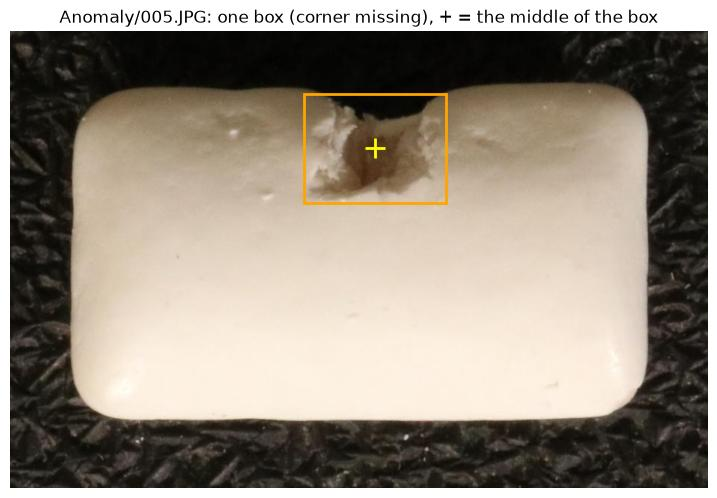

In [14]:
for _, photo in photos[photos["is_defect"]].iterrows():
    boxes = mask_to_boxes(open_mask(photo["crop_mask"]), SPECK_PIXELS, JOIN_GAP, MIN_BOX_SIDE)
    if len(boxes) == 1:
        break
box = boxes[0]
left, top, right, bottom = box["left"], box["top"], box["right"], box["bottom"]

print(f"Photo: {photo['name']} ({photo['defect_types']}), crop {CROP_WIDTH} x {CROP_HEIGHT} pixels")
print(f"Box in pixels: left {left}, top {top}, right {right}, bottom {bottom} ({box['defect type']})\n")
print(f"class    = mask number - 1 = {box['class'] + 1} - 1 = {box['class']}")
print(f"x_center = ({left} + {right}) / 2 / {CROP_WIDTH} = {(left + right) / 2 / CROP_WIDTH:.6f}")
print(f"y_center = ({top} + {bottom}) / 2 / {CROP_HEIGHT} = {(top + bottom) / 2 / CROP_HEIGHT:.6f}")
print(f"width    = ({right} - {left}) / {CROP_WIDTH} = {(right - left) / CROP_WIDTH:.6f}")
print(f"height   = ({bottom} - {top}) / {CROP_HEIGHT} = {(bottom - top) / CROP_HEIGHT:.6f}")
print(f"\nThe line in its label file: {yolo_line(box, CROP_WIDTH, CROP_HEIGHT)}")

fig, ax = plt.subplots(figsize=(9, 6.2))
ax.imshow(open_crop(photo["crop_image"]))
draw_boxes(ax, [box])
ax.plot((left + right) / 2, (top + bottom) / 2, "+", color="yellow", markersize=14, markeredgewidth=2)
ax.set_title(f"{photo['name']}: one box ({box['defect type']}), + = the middle of the box")
ax.axis("off")
plt.show()

> **What we see:** the box sits around the broken-off piece at the top of the gum. Its line says: class 1 (*corner missing*); the middle of the box is at x 0.522629 and y 0.255757, so a little right of the middle of the crop and in its upper part; the box is 0.204741 of the crop wide and 0.238487 high, so about a fifth of the width and a quarter of the height. These numbers do not depend on the picture size, so the box is still right when YOLO resizes the crop.

## Step 2: From a Mask to Boxes, Step by Step

### Follow One Mask

> We take the defect type with the most pieces in one cropped mask (notebook 2.1 found it: a scratch drawn as a broken line) and show each step of `mask_to_boxes()` on a close-up:
>
> 1. **The mask:** one box per piece would give many tiny boxes.
> 2. **Drop the specks:** red = pieces we keep, blue = specks (fewer than `SPECK_PIXELS` pixels) we drop.
> 3. **Grow the pieces** by `JOIN_GAP // 2` = 10 pixels (yellow). Pieces whose grown areas touch belong to one group.
> 4. **The final boxes:** one box around the kept pixels of each group. The dropped specks stay blue: they are in no box.

Anomaly/068.JPG, scratches: 32 pieces, 30 specks dropped, 2 pieces kept, 2 groups, 2 boxes


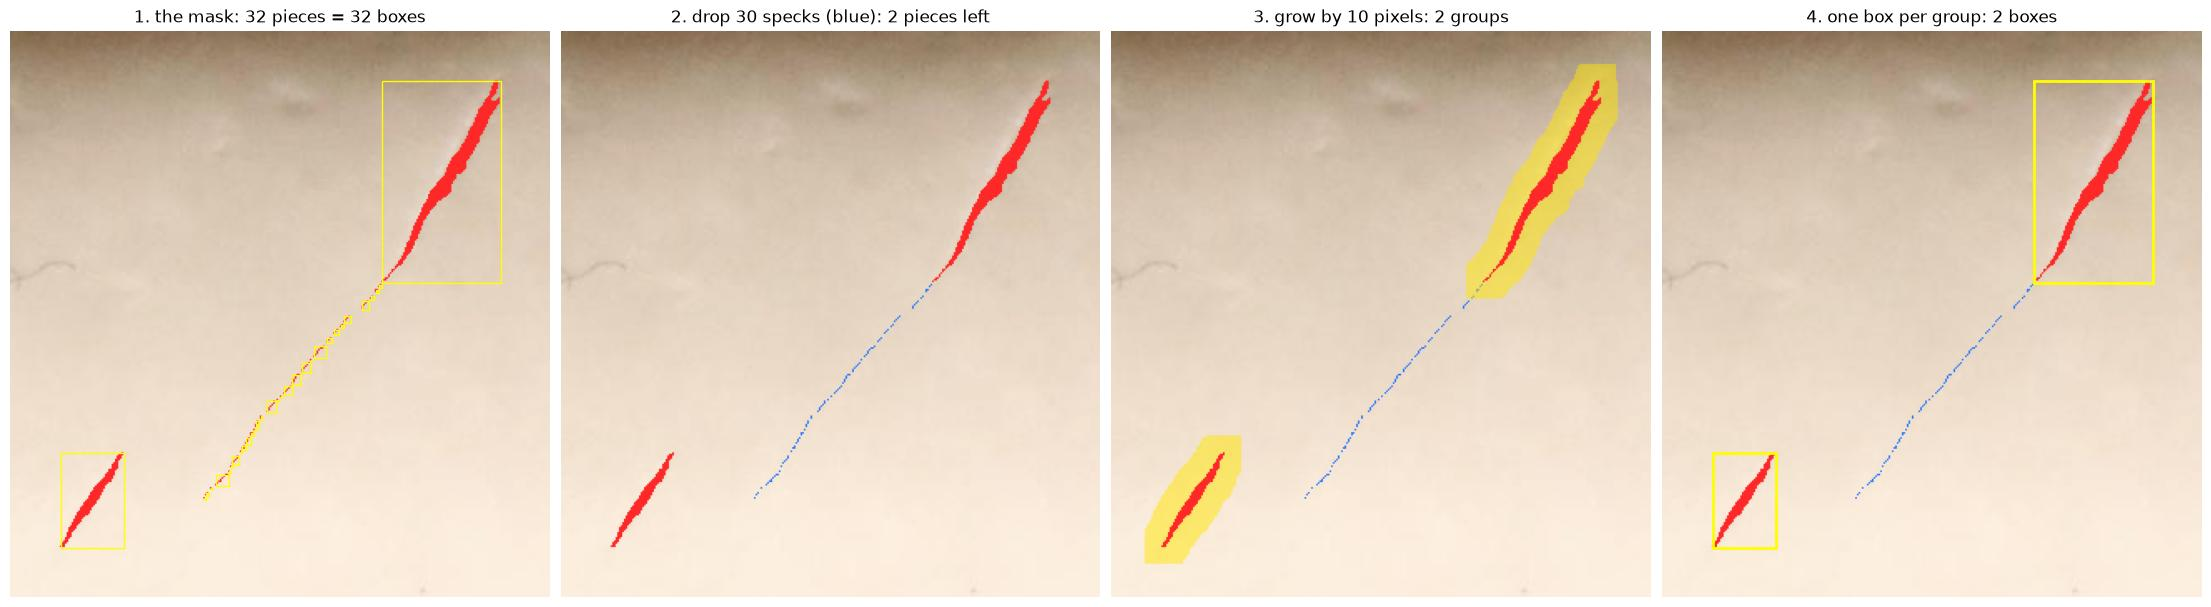

In [15]:
rows = []
for i, photo in photos[photos["is_defect"]].iterrows():
    mask = open_mask(photo["crop_mask"])
    for number, name in MASK_CODE.items():
        pieces, sizes = find_pieces(mask == number)
        rows.append({"photo": i, "number": number, "pieces": int((sizes > 0).sum())})
most = pd.DataFrame(rows).sort_values("pieces", ascending=False).iloc[0]
photo = photos.loc[most["photo"]]
number = int(most["number"])

crop = open_crop(photo["crop_image"])
type_pixels = open_mask(photo["crop_mask"]) == number
pieces, sizes = find_pieces(type_pixels)
kept = sizes[pieces] >= SPECK_PIXELS
grown = ndimage.binary_dilation(kept, structure=TOUCHING, iterations=JOIN_GAP // 2)
groups, n_groups = ndimage.label(grown, structure=TOUCHING)
final = [b for b in mask_to_boxes(open_mask(photo["crop_mask"]), SPECK_PIXELS, JOIN_GAP, MIN_BOX_SIDE)
        if b["class"] == number - 1]
area = close_up_box(type_pixels, margin=30)
view = (slice(area[1], area[3]), slice(area[0], area[2]))
shift = (area[0], area[1])

n_pieces, n_kept = int((sizes > 0).sum()), int((sizes >= SPECK_PIXELS).sum())
print(f"{photo['name']}, {MASK_CODE[number]}: {n_pieces} pieces, {n_pieces - n_kept} specks dropped, "
    f"{n_kept} pieces kept, {n_groups} groups, {len(final)} boxes")

painted = crop.copy()
painted[type_pixels] = [255, 40, 40]
specks_blue = crop.copy()
specks_blue[kept] = [255, 40, 40]
specks_blue[type_pixels & ~kept] = [40, 120, 255]
grown_view = specks_blue.copy()
grown_view[grown & ~kept] = (0.5 * grown_view[grown & ~kept] + 0.5 * np.array([255, 230, 0])).astype(np.uint8)

fig, axes = plt.subplots(1, 4, figsize=(22, 6), layout="constrained")
axes[0].imshow(painted[view])
for rows_slice, cols_slice in ndimage.find_objects(pieces):
    axes[0].add_patch(Rectangle((cols_slice.start - shift[0], rows_slice.start - shift[1]),
                                cols_slice.stop - cols_slice.start, rows_slice.stop - rows_slice.start,
                                fill=False, edgecolor="yellow", linewidth=1))
axes[0].set_title(f"1. the mask: {n_pieces} pieces = {n_pieces} boxes")
axes[1].imshow(specks_blue[view])
axes[1].set_title(f"2. drop {n_pieces - n_kept} specks (blue): {n_kept} pieces left")
axes[2].imshow(grown_view[view])
axes[2].set_title(f"3. grow by {JOIN_GAP // 2} pixels: {n_groups} groups")
axes[3].imshow(specks_blue[view])
draw_boxes(axes[3], final, color="yellow", shift=shift)
axes[3].set_title(f"4. one box per group: {len(final)} boxes")
for ax in axes:
    ax.axis("off")
plt.show()

> **What we see:** in Anomaly/068.JPG one scratch line is drawn as 32 pieces. 30 of them are specks of a few pixels: a dotted line that YOLO could never learn from as 30 separate boxes. 2 real pieces are left. They lie far apart, so growing them by 10 pixels does not join them, and YOLO gets 2 boxes that each hold a clear part of the scratch, instead of 32 tiny ones. Step 3 shows masks where joining does change the boxes.

## Step 3: Why Join Pieces up to 20 Pixels Apart, and Not More?

### Try Three Join Gaps

> We make the boxes for all defect photos three times: with `join_gap` = 0 (never join), 20 (our setting) and 60 (join a lot). The table counts the boxes for each defect type. Then we show two examples, both chosen by the code:
>
> - **Top row:** the defect type in one photo that loses the most boxes from 0 to 20.
> - **Bottom row:** the defect type in one photo that loses the most boxes from 20 to 60.
>
> Red: the defect pixels. Yellow: the boxes.

In [16]:
JOIN_OPTIONS = [0, JOIN_GAP, 60]
rows = []
for i, photo in tqdm(photos[photos["is_defect"]].iterrows(), total=photos["is_defect"].sum(),
                    desc="Making boxes with 3 join gaps"):
    mask = open_mask(photo["crop_mask"])
    for gap in JOIN_OPTIONS:
        for box in mask_to_boxes(mask, SPECK_PIXELS, gap, MIN_BOX_SIDE):
            rows.append({"photo": i, "defect type": box["defect type"], "join gap": gap})
counts = pd.DataFrame(rows).groupby(["photo", "defect type", "join gap"]).size().unstack(fill_value=0)

print("Boxes in all defect photos:", ", ".join(f"join gap {gap}: {counts[gap].sum()}" for gap in JOIN_OPTIONS))
counts.groupby("defect type").sum()

Making boxes with 3 join gaps:   0%|          | 0/100 [00:00<?, ?it/s]

Making boxes with 3 join gaps: 100%|██████████| 100/100 [00:29<00:00,  3.41it/s]

Boxes in all defect photos: join gap 0: 215, join gap 20: 205, join gap 60: 191


join gap,0,20,60
defect type,,,
chunk of gum missing,56,54,50
corner missing,47,46,46
scratches,29,26,25
similar colour spot,25,25,25
small cracks,58,54,45


Example: Anomaly/008.JPG, small cracks: join gap 0: 5 boxes, join gap 20: 3 boxes, join gap 60: 2 boxes
Example: Anomaly/038.JPG, small cracks: join gap 0: 3 boxes, join gap 20: 3 boxes, join gap 60: 1 boxes


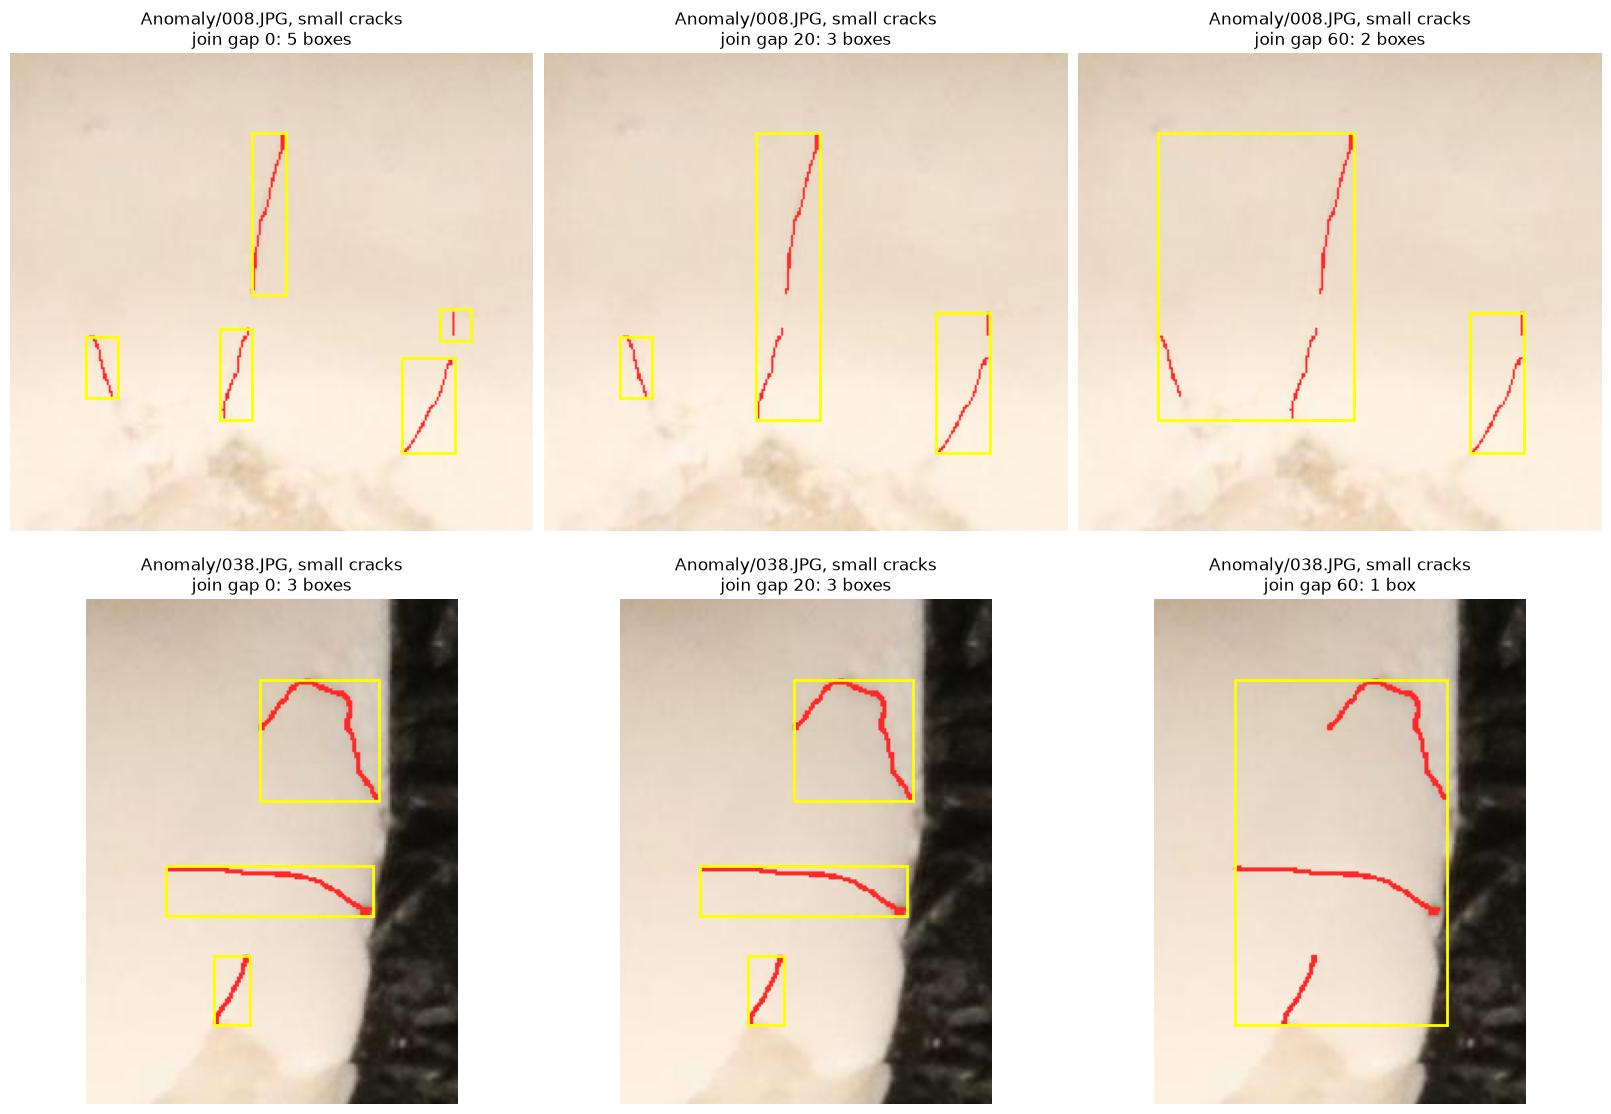

In [17]:
examples = [(counts[0] - counts[JOIN_GAP]).idxmax(), (counts[JOIN_GAP] - counts[60]).idxmax()]
for i, name in examples:
    print(f"Example: {photos.loc[i, 'name']}, {name}: " + ", ".join(f"join gap {gap}: {counts.loc[(i, name), gap]} boxes" for gap in JOIN_OPTIONS))

fig, axes = plt.subplots(len(examples), len(JOIN_OPTIONS), figsize=(16, 11), layout="constrained")
for line, (i, name) in enumerate(examples):
    photo = photos.loc[i]
    mask = open_mask(photo["crop_mask"])
    type_pixels = mask == TYPE_CODE[name]
    area = close_up_box(type_pixels, margin=40)
    painted = open_crop(photo["crop_image"]).copy()
    painted[type_pixels] = [255, 40, 40]
    for col, gap in enumerate(JOIN_OPTIONS):
        boxes = [b for b in mask_to_boxes(mask, SPECK_PIXELS, gap, MIN_BOX_SIDE) if b["defect type"] == name]
        axes[line, col].imshow(painted[area[1]:area[3], area[0]:area[2]])
        draw_boxes(axes[line, col], boxes, color="yellow", shift=(area[0], area[1]))
        axes[line, col].set_title(f"{photo['name']}, {name}\njoin gap {gap}: {len(boxes)} box" + ("es" if len(boxes) != 1 else ""))
        axes[line, col].axis("off")
plt.show()

> **What we see:**
>
> - Joining changes fewer boxes than dropping specks: 215 boxes without joining, 205 with a gap of 20, 191 with a gap of 60.
> - **Top row (Anomaly/008.JPG):** with a gap of 0, a crack that is broken into parts gets one box per part. With 20, the parts of one crack become one box, which is what a person would draw. With 60, a separate crack on the left is already pulled into a big box.
> - **Bottom row (Anomaly/038.JPG):** with a gap of 60, three separate cracks are joined into one big box that is mostly clean gum. With 20 they keep their own boxes.
>
> So 20 pixels joins the broken parts of one defect, but keeps separate defects apart.
>
> We looked at the masks of all photos to choose this rule. That is fine: this rule only decides how the labels are written, the same way for every photo. It is not a model setting, and no model score was used to choose it.

## Step 4: Why Make Thin Boxes Wider?

### What YOLO Does with Thin Boxes

> While YOLO trains, it changes every picture a little at random (**augmentation**), so it learns from more variety. One change makes the picture smaller or bigger: by default down to half its size (Ultralytics setting `scale` = 0.5). After every change, YOLO **throws away boxes that became 2 pixels thin or less**, as if there was no defect.
>
> A thin crack gives a thin box. To see how thin, we make the boxes once without widening (`min_side` = 0 keeps every box tight) and look at the thinnest one. Then we compare it with the same box after widening to `MIN_BOX_SIDE`.

In [18]:
rows = []
for i, photo in photos[photos["is_defect"]].iterrows():
      for n, box in enumerate(mask_to_boxes(open_mask(photo["crop_mask"]), SPECK_PIXELS, JOIN_GAP, 0)):
        rows.append({"photo": i, "box number": n, **box,
                  "thin side": min(box["right"] - box["left"], box["bottom"] - box["top"])})
tight_boxes = pd.DataFrame(rows)
thin = tight_boxes[tight_boxes["thin side"] < MIN_BOX_SIDE]

print(f"Boxes thinner than {MIN_BOX_SIDE} pixels: {len(thin)} of {len(tight_boxes)}")
print("By defect type:", thin["defect type"].value_counts().to_dict())
thinnest = tight_boxes.loc[tight_boxes["thin side"].idxmin()]
print(f"Thinnest box: {thinnest['right'] - thinnest['left']} x {thinnest['bottom'] - thinnest['top']} pixels "
      f"({photos.loc[thinnest['photo'], 'name']}, {thinnest['defect type']})")
print(f"At half size its thin side is {thinnest['thin side'] / 2} pixels; "
      f"a box widened to {MIN_BOX_SIDE} pixels stays at least {MIN_BOX_SIDE / 2:.0f} pixels")

Boxes thinner than 16 pixels: 16 of 205
By defect type: {'small cracks': 12, 'scratches': 3, 'chunk of gum missing': 1}
Thinnest box: 7 x 78 pixels (Anomaly/051.JPG, small cracks)
At half size its thin side is 3.5 pixels; a box widened to 16 pixels stays at least 8 pixels


> The thinnest box, before (red dashed) and after widening (yellow). `mask_to_boxes()` makes the boxes of a photo in the same order whatever `min_side` is, so box number n is the same defect with and without widening. The close-up shows 40 pixels around the box.

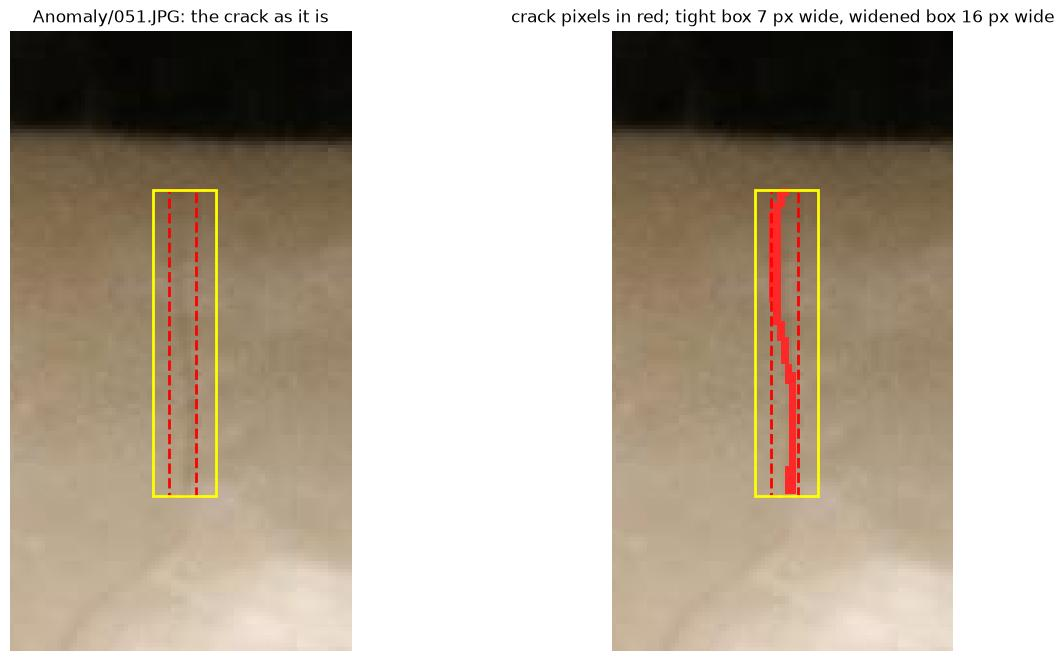

In [19]:
photo = photos.loc[thinnest["photo"]]
widened = mask_to_boxes(open_mask(photo["crop_mask"]), SPECK_PIXELS, JOIN_GAP, MIN_BOX_SIDE)[thinnest["box number"]]
type_pixels = open_mask(photo["crop_mask"]) == TYPE_CODE[thinnest["defect type"]]
area = (max(thinnest["left"] - 40, 0), max(thinnest["top"] - 40, 0),
        min(thinnest["right"] + 40, CROP_WIDTH), min(thinnest["bottom"] + 40, CROP_HEIGHT))
crop = open_crop(photo["crop_image"])

fig, axes = plt.subplots(1, 2, figsize=(12, 6.5), layout="constrained")
for ax, show_red in zip(axes, [False, True]):
    picture = crop.copy()
    if show_red:
        picture[type_pixels] = [255, 40, 40]
    ax.imshow(picture[area[1]:area[3], area[0]:area[2]])
    draw_boxes(ax, [thinnest], color="red", shift=(area[0], area[1]), linestyle="--")
    draw_boxes(ax, [widened], color="yellow", shift=(area[0], area[1]))
    ax.axis("off")
axes[0].set_title(f"{photo['name']}: the crack as it is")
axes[1].set_title(f"crack pixels in red; tight box {thinnest['right'] - thinnest['left']} px wide, "
                f"widened box {widened['right'] - widened['left']} px wide")
plt.show()

> **What we see:**
>
> - 16 of the 205 boxes are thinner than 16 pixels, 12 of them *small cracks*. The thinnest is only 7 pixels wide.
> - At half size, 7 pixels become 3.5 pixels: close to YOLO's limit of 2 pixels, and below it if step 4 trains on smaller pictures. Then YOLO would sometimes learn that a crack is "nothing".
> - Widened to 16 pixels, the box stays at least 8 pixels even at half size. The crack is still in the middle of the box, with a little gum on both sides.

## Step 5: Make the Boxes for All Defect Photos

### All Boxes in One Table

> We run `mask_to_boxes()` with our settings on every cropped mask. We also count all pieces, to see how many specks are dropped.
>
> The box table `yolo_boxes.csv` gets one row per box, with the photo (`image` and `crop_image`) and the box columns of `mask_to_boxes()`.

In [20]:
box_rows, piece_rows = [], []
for i, photo in tqdm(photos[photos["is_defect"]].iterrows(), total=photos["is_defect"].sum(), desc="Making boxes"):
    mask = open_mask(photo["crop_mask"])
    for number, name in MASK_CODE.items():
        pieces, sizes = find_pieces(mask == number)
        piece_rows += [{"photo": i, "defect type": name, "pixels": int(size)} for size in sizes[1:]]
    for box in mask_to_boxes(mask, SPECK_PIXELS, JOIN_GAP, MIN_BOX_SIDE):
        box_rows.append({"image": photo["image"], "crop_image": photo["crop_image"], **box})
boxes = pd.DataFrame(box_rows)
all_pieces = pd.DataFrame(piece_rows)
boxes.to_csv(BOX_TABLE_FILE, index=False)

specks = all_pieces[all_pieces["pixels"] < SPECK_PIXELS]
print(f"Pieces in all cropped masks: {len(all_pieces)} | specks dropped: {len(specks)} | boxes: {len(boxes)} "
        f"| widened boxes: {boxes['widened'].sum()}")
print(f"Biggest speck: {specks['pixels'].max()} pixels | smallest pieces kept: "
        f"{sorted(all_pieces.loc[all_pieces['pixels'] >= SPECK_PIXELS, 'pixels'])[:3]} pixels")
print(f"Boxes per defect photo: from {boxes.groupby('image').size().min()} to {boxes.groupby('image').size().max()}")
print(f"Defect photos without any box: {photos['is_defect'].sum() - boxes['image'].nunique()}")

by_type = pd.DataFrame({
    "pieces": all_pieces.groupby("defect type").size(),
    "specks dropped": specks.groupby("defect type").size(),
    "boxes": boxes.groupby("defect type").size(),
    "widened boxes": boxes.groupby("defect type")["widened"].sum(),
}).fillna(0).astype(int)
by_type

Making boxes: 100%|██████████| 100/100 [00:14<00:00,  6.82it/s]

Pieces in all cropped masks: 255 | specks dropped: 40 | boxes: 205 | widened boxes: 16
Biggest speck: 9 pixels | smallest pieces kept: [12, 30, 43] pixels
Boxes per defect photo: from 1 to 5
Defect photos without any box: 0


,pieces,specks dropped,boxes,widened boxes
defect type,,,,
chunk of gum missing,56,0,54,1
corner missing,51,4,46,0
scratches,63,34,26,3
similar colour spot,25,0,25,0
small cracks,60,2,54,12


### Defect Types Without a Box

> The photo list says which defect types each photo has. Here we look for photos where a listed defect type got no box, because all of its pieces were specks.

In [21]:
rows = []
for _, photo in photos[photos["is_defect"]].iterrows():
    listed = set(photo["defect_types"].split(","))
    boxed = set(boxes.loc[boxes["image"] == photo["image"], "defect type"])
    for name in sorted(listed - boxed):
        rows.append({"photo": photo["name"], "defect types in the photo list": photo["defect_types"],
                    "type without a box": name,
                    "pixels of this type": int((open_mask(photo["crop_mask"]) == TYPE_CODE[name]).sum())})
pd.DataFrame(rows)

,photo,defect types in the photo list,type without a box,pixels of this type
0,Anomaly/057.JPG,"chunk of gum missing,scratches,small cracks",small cracks,1


> **What we see:**
>
> - 255 pieces become 205 boxes. 40 specks are dropped. The biggest speck has 9 pixels, while the smallest pieces we keep have 12, 30 and 43 pixels. So the specks are clearly a separate group, and `SPECK_PIXELS` = 10 lies in the gap between the two.
> - Most specks are *scratches* (34 of 40): the broken scratch lines we saw in Step 2.
> - Every defect photo keeps at least 1 box (at most 5).
> - Only one listed defect type gets no box: the *small cracks* of Anomaly/057.JPG, which has only 1 crack pixel (notebook 2.1). The photo still has its other boxes, so it still counts as a defect photo for YOLO. And every later score that is reported per defect type uses the photo list, not the boxes.

### What YOLO Learns From When k = 5

> The 5 defect photos of split 1 that YOLO gets in its smallest experiment (`yolo_5` in the split file), with their final boxes. The colour shows the class.

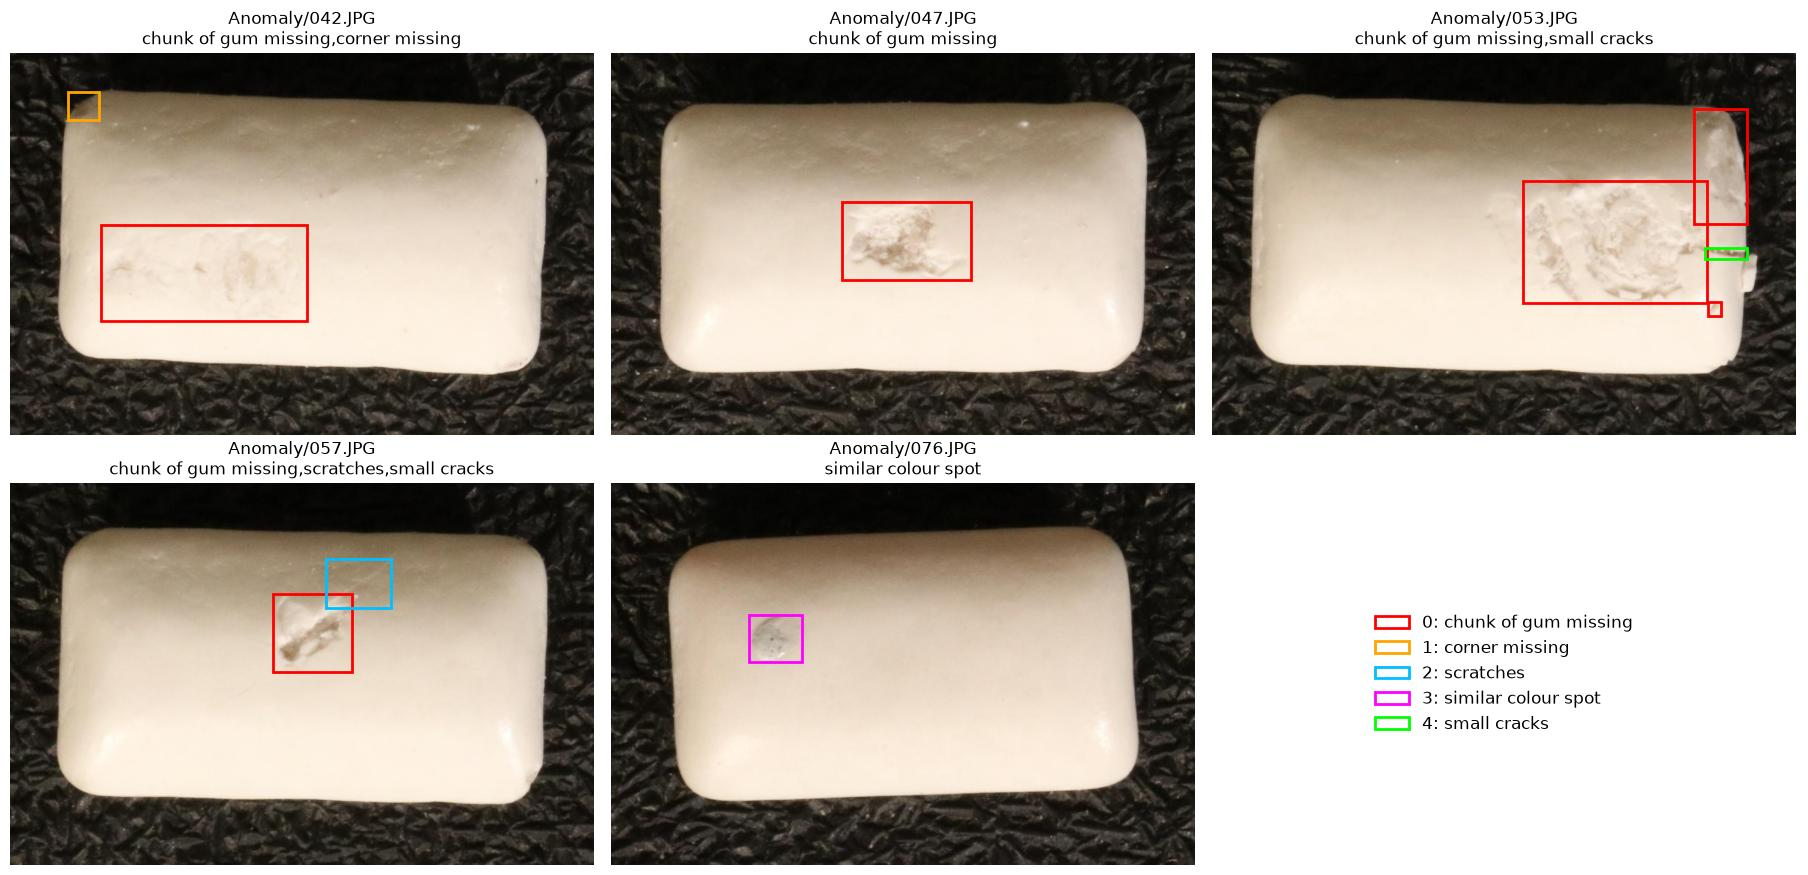

In [22]:
first_five = splits[1].loc[splits[1]["yolo_5"] & splits[1]["is_defect"], "image"]
shown = photos[photos["image"].isin(first_five)]

fig, axes = plt.subplots(2, 3, figsize=(18, 8.6), layout="constrained")
for ax, (_, photo) in zip(axes.ravel(), shown.iterrows()):
    ax.imshow(open_crop(photo["crop_image"]))
    draw_boxes(ax, boxes[boxes["image"] == photo["image"]].to_dict("records"))
    ax.set_title(f"{photo['name']}\n{photo['defect_types']}")
    ax.axis("off")
axes[-1, -1].legend(handles=[Patch(edgecolor=color, facecolor="none", linewidth=2, label=f"{c}: {CLASS_NAMES[c]}")
                            for c, color in CLASS_COLORS.items()], loc="center", fontsize=12, frameon=False)
axes[-1, -1].axis("off")
plt.show()

## Step 6: Write the Label Files

### One Label File per Crop

> For every crop we write its label file, at the path from `label_path()`:
>
> - a defect crop gets one line per box, made with `yolo_line()`,
> - a normal crop gets an **empty** file: it is a background picture, with nothing to find.
>
> The 6 photos that notebook 1.2 left out also get a label file, but they are in no list (Step 7), so YOLO never sees them.
>
> Running this cell again replaces the files with the same files.

In [23]:
for folder in ["labels/Normal", "labels/Anomaly"]:
    os.makedirs(full_path(CROP_DIR, folder), exist_ok=True)

lines_of = {image: [] for image in photos["image"]}
for box in boxes.to_dict("records"):
    lines_of[box["image"]].append(yolo_line(box, CROP_WIDTH, CROP_HEIGHT))
for _, photo in photos.iterrows():
    write_lines(full_path(CROP_DIR, label_path(photo["crop_image"])), lines_of[photo["image"]])

n_empty = sum(len(lines) == 0 for lines in lines_of.values())
print(f"Label files written: {len(lines_of)} ({n_empty} empty, {len(lines_of) - n_empty} with boxes)")
print(f"Lines in all label files: {sum(len(lines) for lines in lines_of.values())} (one per box)")

example = photos[photos["is_defect"]].iloc[0]
print(f"\nExample: {label_path(example['crop_image'])} (the label file of {example['name']}, {example['defect_types']})")
print(open(full_path(CROP_DIR, label_path(example["crop_image"])), encoding="utf-8").read())

Label files written: 603 (503 empty, 100 with boxes)
Lines in all label files: 205 (one per box)

Example: labels/Anomaly/000.txt (the label file of Anomaly/000.JPG, chunk of gum missing,scratches,small cracks)
0 0.267780 0.431743 0.154095 0.287829
2 0.402478 0.305921 0.078664 0.072368
4 0.252155 0.208059 0.025862 0.116776
4 0.342672 0.442434 0.032328 0.039474
4 0.162716 0.623355 0.077586 0.131579



## Step 7: Write the Photo Lists

### Why Extra Copies of the Defect Photos?

> In the k = 5 experiment, YOLO has 347 normal train photos and only 5 defect photos. If every photo were in the list once, 98.6% of the pictures would have no defect (the column `background % without copies` in the table below). YOLO would learn that "no defect" is almost always right, and it would hardly learn what a defect looks like. (Ultralytics advises about 0 to 10% background pictures for normal object detection. We keep many more, on purpose: our normal photos teach YOLO not to raise false alarms on good gum, and that matters a lot for our score.)
>
> So we **oversample**: every defect photo is written several times in the train list (`copies_for()`), so that about one line in three is a defect photo. When YOLO trains, it also glues 4 random pictures of the list into one (**mosaic**). With one defect line in three, the chance that a mosaic holds at least one defect photo is *1 − (1 − 1/3)⁴*, printed below the lists. So most training pictures contain a defect, next to plenty of good gum.
>
> A second reason: every train list gets about the same number of lines, whatever k is. So one epoch has about the same number of training steps for k = 5 and for k = 40, and the experiments stay comparable.
>
> The copies are exact copies, but YOLO changes them randomly every time it sees them (augmentation), so it hardly ever sees exactly the same picture twice.

### Make the Lists

> For every split:
>
> - **Train lists** (one per k): all normal train photos once, then each of the k labeled defect photos (`yolo_k` in the split file) `copies` times. `for _ in range(copies)` repeats a line `copies` times; `_` is a name for a number we do not need.
> - **Validation list:** all validation photos once. YOLO uses it during training to show how well it is doing after every epoch. It never learns from these photos.
> - **Test list:** all test photos once, for the final score in step 5.
>
> Every line is the path of a crop, starting with `./`. YOLO replaces `./` with the folder of the list file, so the lists keep working when the project folder is moved to another place or computer.

In [24]:
list_rows = []
for s, split in splits.items():
    split = split.merge(photos[["image", "crop_image"]], on="image")
    normal_train = split.loc[(split["split"] == "train") & ~split["is_defect"], "crop_image"]
    for k in LABEL_STEPS:
        defect_train = split.loc[split[f"yolo_{k}"] & split["is_defect"], "crop_image"]
        copies = copies_for(k, len(normal_train), DEFECT_SHARE)
        lines = ["./" + p for p in normal_train] + ["./" + p for p in defect_train for _ in range(copies)]
        write_lines(full_path(CROP_DIR, f"split_{s}_k{k}_train.txt"), lines)
        list_rows.append({"split": s, "k": k, "normal lines": len(normal_train), "defect photos": len(defect_train),
                          "background % without copies": round(100 * len(normal_train) / (len(normal_train) + k), 1),
                          "copies of each": copies, "defect lines": len(defect_train) * copies, "all lines": len(lines),
                          "defect share %": round(100 * len(defect_train) * copies / len(lines), 1)})
    for part in ["val", "test"]:
        part_images = split.loc[split["split"] == part, ["crop_image", "is_defect"]]
        write_lines(full_path(CROP_DIR, f"split_{s}_{part}.txt"), ["./" + p for p in part_images["crop_image"]])
        print(f"split_{s}_{part}.txt: {len(part_images)} lines "
            f"({(~part_images['is_defect']).sum()} normal, {part_images['is_defect'].sum()} defect)")

list_table = pd.DataFrame(list_rows)
mosaic_chance = 1 - (1 - DEFECT_SHARE) ** 4
print(f"\nChance that a mosaic of 4 pictures holds at least one defect photo: 1 - (1 - 1/3)^4 = {mosaic_chance:.0%}")
list_table

split_1_val.txt: 60 lines (50 normal, 10 defect)
split_1_test.txt: 150 lines (100 normal, 50 defect)
split_2_val.txt: 60 lines (50 normal, 10 defect)
split_2_test.txt: 150 lines (100 normal, 50 defect)
split_3_val.txt: 60 lines (50 normal, 10 defect)
split_3_test.txt: 150 lines (100 normal, 50 defect)

Chance that a mosaic of 4 pictures holds at least one defect photo: 1 - (1 - 1/3)^4 = 80%


,split,k,normal lines,defect photos,background % without copies,copies of each,defect lines,all lines,defect share %
0,1,5,347,5,98.6,35,175,522,33.5
1,1,10,347,10,97.2,17,170,517,32.9
2,1,20,347,20,94.6,9,180,527,34.2
3,1,40,347,40,89.7,4,160,507,31.6
4,2,5,347,5,98.6,35,175,522,33.5
5,2,10,347,10,97.2,17,170,517,32.9
6,2,20,347,20,94.6,9,180,527,34.2
7,2,40,347,40,89.7,4,160,507,31.6
8,3,5,347,5,98.6,35,175,522,33.5
9,3,10,347,10,97.2,17,170,517,32.9


In [25]:
example = open(full_path(CROP_DIR, "split_1_k5_train.txt"), encoding="utf-8").read().splitlines()
print(f"split_1_k5_train.txt has {len(example)} lines. The first 3 lines:")
print("\n".join(example[:3]))
defect_lines = [line for line in example if "/Anomaly/" in line]
print(f"\nDefect lines: {len(defect_lines)}, for {len(set(defect_lines))} different photos. The first 3 defect lines:")
print("\n".join(defect_lines[:3]))

split_1_k5_train.txt has 522 lines. The first 3 lines:
./images/Normal/000.png
./images/Normal/001.png
./images/Normal/002.png

Defect lines: 175, for 5 different photos. The first 3 defect lines:
./images/Anomaly/042.png
./images/Anomaly/042.png
./images/Anomaly/042.png


> **What we see:**
>
> - Without copies, 89.7% (k = 40) to 98.6% (k = 5) of the pictures would be background.
> - Each train list has the 347 normal train photos once. The defect photos get 35 copies each for k = 5, 17 for k = 10, 9 for k = 20 and 4 for k = 40. That gives 31.6% to 34.2% defect lines and 507 to 527 lines per list. A mosaic then holds at least one defect photo 80% of the time.
> - The k = 5 list of split 1 has 522 lines, and its 175 defect lines are 35 copies of 5 photos.
> - Every validation list has 60 photos (50 normal, 10 defect) and every test list 150 (100 normal, 50 defect), the same as the split files.

## Step 8: Write the Dataset Files

### One Dataset File per Experiment

> YOLO starts training from a dataset file (`.yaml`). Ours have three lines with list files and the class names:
>
> - `train`: the train list of this split and this k.
> - `val`: the validation list of this split.
> - `test`: the test list of this split. YOLO only uses it when we ask for the final score; training never reads it.
> - `names`: the 5 classes.
>
> There is no `path` line. Then YOLO looks for the list files in the folder of the dataset file itself, so we do not have to write a full path that only works on one computer.
>
> In the main experiment (step 4), YOLO trains with the setting `single_cls=True`, which merges the 5 classes into one class: "defect" (Ultralytics calls it *item*). Our score only asks "defect or not?", and with only 5 labeled photos most classes would have just one example. One extra demo model uses the 5 classes, so it can also name the defect type.

In [26]:
yaml_files = []
for s in SPLITS:
    for k in LABEL_STEPS:
        lines = [f"train: split_{s}_k{k}_train.txt", f"val: split_{s}_val.txt", f"test: split_{s}_test.txt", "names:"]
        lines += [f"  {number}: {name}" for number, name in CLASS_NAMES.items()]
        yaml_files.append(f"split_{s}_k{k}.yaml")
        write_lines(full_path(CROP_DIR, yaml_files[-1]), lines)

print(f"Dataset files written: {len(yaml_files)}")
print(", ".join(yaml_files))
print(f"\nContent of {yaml_files[0]}:")
print(open(full_path(CROP_DIR, yaml_files[0]), encoding="utf-8").read())

Dataset files written: 12
split_1_k5.yaml, split_1_k10.yaml, split_1_k20.yaml, split_1_k40.yaml, split_2_k5.yaml, split_2_k10.yaml, split_2_k20.yaml, split_2_k40.yaml, split_3_k5.yaml, split_3_k10.yaml, split_3_k20.yaml, split_3_k40.yaml

Content of split_1_k5.yaml:
train: split_1_k5_train.txt
val: split_1_val.txt
test: split_1_test.txt
names:
  0: chunk of gum missing
  1: corner missing
  2: scratches
  3: similar colour spot
  4: small cracks



### All Files in the Crops Folder

> A look at what is now in `data/processed/crops/`: the folders with how many files they hold, and the files directly in the folder.

In [27]:
for folder in ["images/Normal", "images/Anomaly", "masks/Anomaly", "labels/Normal", "labels/Anomaly"]:
    print(f"{folder + '/':18} {len(os.listdir(full_path(CROP_DIR, folder)))} files")
top_files = sorted(f for f in os.listdir(CROP_DIR) if os.path.isfile(os.path.join(CROP_DIR, f)))
print(f"\nFiles directly in the folder: {len(top_files)}")
print(", ".join(top_files))

images/Normal/     503 files
images/Anomaly/    100 files
masks/Anomaly/     100 files
labels/Normal/     503 files
labels/Anomaly/    100 files

Files directly in the folder: 32
crop_boxes.csv, split_1_k10.yaml, split_1_k10_train.txt, split_1_k20.yaml, split_1_k20_train.txt, split_1_k40.yaml, split_1_k40_train.txt, split_1_k5.yaml, split_1_k5_train.txt, split_1_test.txt, split_1_val.txt, split_2_k10.yaml, split_2_k10_train.txt, split_2_k20.yaml, split_2_k20_train.txt, split_2_k40.yaml, split_2_k40_train.txt, split_2_k5.yaml, split_2_k5_train.txt, split_2_test.txt, split_2_val.txt, split_3_k10.yaml, split_3_k10_train.txt, split_3_k20.yaml, split_3_k20_train.txt, split_3_k40.yaml, split_3_k40_train.txt, split_3_k5.yaml, split_3_k5_train.txt, split_3_test.txt, split_3_val.txt, yolo_boxes.csv


## Summary

> **What this notebook did**
>
> - Turned the 100 cropped masks into 205 YOLO boxes: specks under 10 pixels dropped, pieces of one type at most 20 pixels apart joined, boxes thinner than 16 pixels widened to 16.
> - Wrote one label file per crop (empty for normal photos) and saved all boxes in `yolo_boxes.csv`.
> - Wrote 12 train lists (3 splits × 4 values of k), with the defect photos copied so they make about one third of each list, and a validation and a test list for each split.
> - Wrote 12 dataset files that YOLO can train from directly.
>
> **Data leakage:** each train list only holds train photos of its own split, and the left-out photos of notebook 1.2 are in no list. Notebook 3.3 checks this, and every other file of step 3.
>
> **Next:** `notebooks/3_preprocessing/3.3_check_preprocessing.ipynb`